# 03 · Detailed Model Results — Predicting Tool Wear (VB)

*New to this project? Start with `02_simple_demo.ipynb`, a short version of this experiment.*

This notebook **reads the saved outputs** of the training scripts and explains them. It does not retrain.
Prerequisite (≈3 min):
```
python scripts/make_dataset.py && python scripts/train.py && python scripts/train_cnn.py && python scripts/report.py
```

## Recap: what the task is
* **Input:** the sensor recording of *one* cutting run (6 channels × 36 s), optionally plus the machine
  settings (material, depth of cut, feed).
* **Output:** the flank wear **VB in mm** of the insert after that run.
* **Data:** 145 runs with a measured VB, coming from 16 inserts ("cases").

## Recap: how models are tested — leave-one-case-out
Consecutive runs of one insert look almost identical. If some runs of an insert were in training and
others in testing, the model could just "recognise the insert" and look great without learning wear.
So each of the 16 folds **holds out one whole insert**, trains on the other 15, and predicts the
held-out one. Every number below is a prediction for an insert the model **never saw**.

**Metrics:** MAE = average |predicted − measured| in mm (main metric). RMSE punishes big misses more.
R² = share of VB variance explained (1 = perfect, 0 = no better than predicting the average).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from milling.evaluate import summarize
from milling.utils import INK_MUTED, MATERIAL_COLORS, PALETTE, set_plot_style
from milling.viz import plot_metrics, plot_pred_vs_true, plot_trajectories

set_plot_style()
pd.set_option("display.precision", 3)
RES, FIG = ROOT / "reports/results", ROOT / "reports/figures"


def save(fig, name):
    fig.savefig(FIG / f"res_{name}.png")


classical = pd.read_csv(RES / "metrics_classical.csv")
cnn_seeds = pd.read_csv(RES / "metrics_cnn_seeds.csv")
oof = pd.read_csv(RES / "oof_classical.csv").merge(
    pd.read_csv(RES / "oof_cnn.csv").drop(columns=["time", "material_name", "target"]), on=["case", "run"]
)
print(f"{len(oof)} held-out predictions from {oof.case.nunique()} inserts")

145 held-out predictions from 16 inserts


## 1. The models and inputs that were compared

| Inputs (feature set) | What goes in | Why it is included |
|---|---|---|
| `process_only` | material, depth of cut, feed | Can the settings alone predict wear? (No — they don't know *how long* the tool has cut.) |
| `process_time` | + cumulative cutting time | A strong **reference**: in a lab, wear grows steadily with time. Not a sensor model. |
| `sensor_only` | 102 hand-crafted signal features | Does the signal itself reveal wear? |
| `sensor_process` | sensor features + settings | The sensor↔wear link depends on material/cut, so give the model the context. |
| raw signals (CNN) | the 6 raw channels + settings | Let a neural network learn its own features. |

**Hand-crafted features** (per channel, from the steady-cut window 8–26 s): mean, std, RMS, min/max,
peak-to-peak, skewness, kurtosis, crest factor, 95th percentile, spectral centroid, dominant frequency,
and the share of power in 5 frequency bands → 17 × 6 = 102 features.

**Models**
* `mean` — always predicts the training average. The "no skill" floor.
* `ridge` — linear regression with shrinkage; inputs are quantile-transformed so an unusual insert can't make it extrapolate wildly.
* `svr` — support-vector regression (smooth non-linear).
* `rf`, `gbr` — random forest and gradient boosting (tree ensembles).
* `cnn` — `WearCNN`: 3 convolution blocks → global average → joined with the settings → small MLP → VB.
  Trained on random 4 s crops of the signal (data augmentation), predicted by averaging 14 sliding crops.

## 2. Every classical experiment (feature set × model)

In [2]:
table = classical.pivot(index="model", columns="feature_set", values="MAE")
table = table.loc[["mean", "ridge", "svr", "rf", "gbr"], ["process_only", "process_time", "sensor_only", "sensor_process"]]
table.style.format("{:.3f}").highlight_min(axis=0, props="font-weight:bold").set_caption("MAE (mm) — lower is better")

feature_set,process_only,process_time,sensor_only,sensor_process
model,,,,
mean,0.200,0.200,0.200,0.200
ridge,0.200,0.133,0.136,0.126
svr,0.213,0.081,0.137,0.128
rf,0.212,0.087,0.137,0.137
gbr,0.223,0.078,0.143,0.143


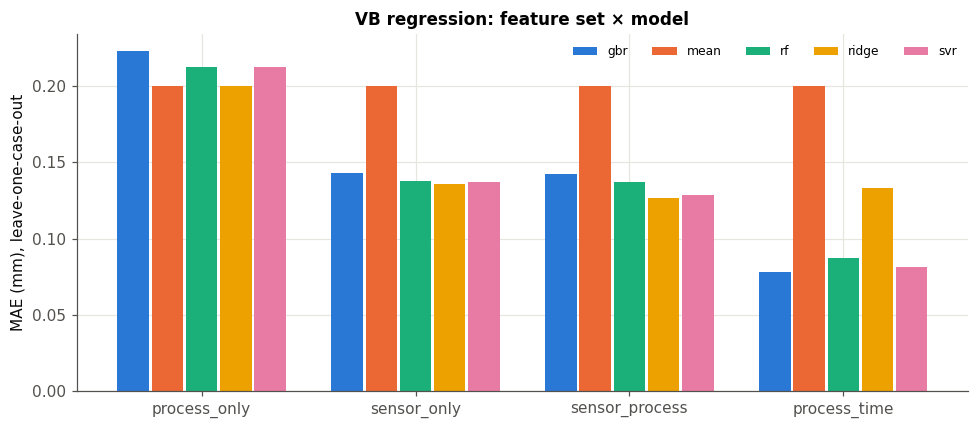

In [3]:
plot_metrics(classical, FIG / "res_all_classical.png")
plt.show()

**How to read this**
* `process_only` ≈ `mean` (0.20 mm): the settings alone carry **no** information about how worn the tool is right now.
* Every model using **sensor** features lands at 0.126–0.143 mm — the signal clearly encodes wear.
* Adding the settings to the sensors helps the linear/SVR models most (0.136 → 0.126).
* Tree models (rf, gbr) are *not* better than ridge here: with only ~130 training runs per fold and 102 features,
  simpler models generalise better to a new insert.

## 3. Headline comparison, including the CNN

In [4]:
rows = []
for fs in classical.feature_set.unique():
    best = classical[(classical.feature_set == fs) & (classical.model != "mean")].sort_values("MAE").iloc[0]
    rows.append({"inputs": fs, "model": best.model, "MAE": best.MAE, "RMSE": best.RMSE, "R2": best.R2})
rows.append({"inputs": "(none)", "model": "mean", **classical[classical.model == "mean"].iloc[0][["MAE", "RMSE", "R2"]].to_dict()})
rows.append({"inputs": "raw signals + process", "model": "cnn (mean of 3 seeds)",
             **cnn_seeds[["MAE", "RMSE", "R2"]].mean().to_dict()})
headline = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
headline

,inputs,model,MAE,RMSE,R2
0,process_time,gbr,0.078,0.124,0.772
1,raw signals + process,cnn (mean of 3 seeds),0.107,0.152,0.658
2,sensor_process,ridge,0.126,0.177,0.533
3,sensor_only,ridge,0.136,0.204,0.381
4,(none),mean,0.200,0.264,-0.037
5,process_only,ridge,0.200,0.266,-0.052


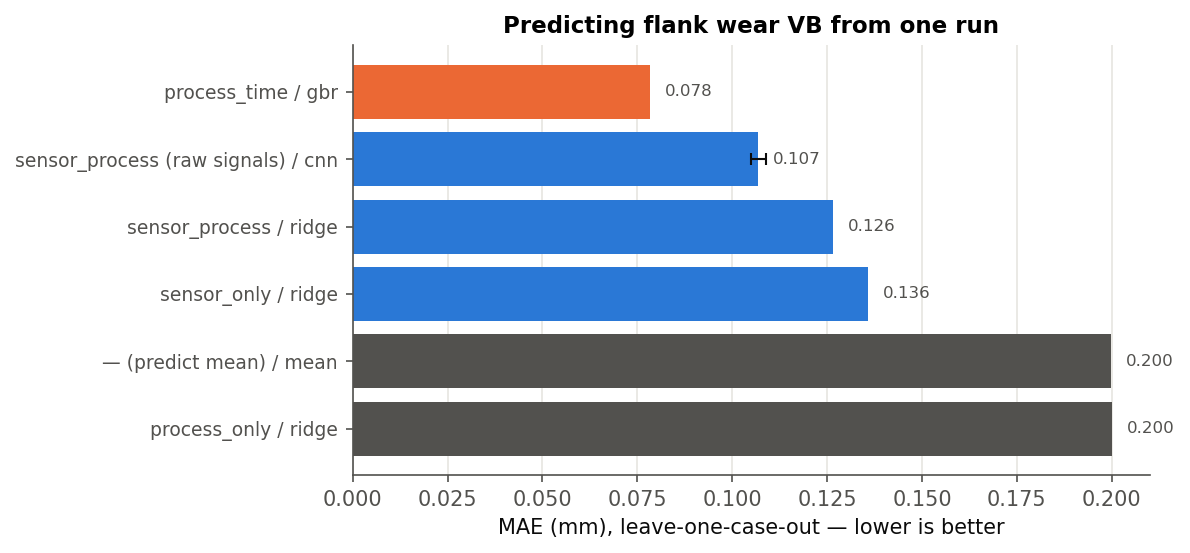

In [5]:
display(Image(FIG / "headline_mae.png"))

* **Best sensor model: the 1D-CNN, MAE ≈ 0.107 mm, R² ≈ 0.66** — about half the error of the no-skill baseline,
  and better than the best hand-crafted-feature model (0.126 mm).
* **Cutting time is still better (0.078 mm).** In this controlled experiment each insert wears smoothly with time,
  so "how long has it cut + what material" is a very good guess. Sensors matter in practice because time can't see
  chipping, a bad batch of material, or a tool whose history is unknown — but on *this* data, beating time is the
  bar a sensor model still has to clear.

### Is the CNN result stable, or a lucky seed?
Neural nets depend on random initialisation. The full CV was repeated with 3 seeds:

In [6]:
cnn_seeds.style.format("{:.3f}", subset=["MAE", "RMSE", "R2", "case_MAE_mean"])

,seed,MAE,RMSE,R2,case_MAE_mean
0,0,0.106,0.150,0.667,0.104
1,1,0.105,0.147,0.679,0.109
2,2,0.109,0.159,0.627,0.115


Spread is ±0.002 mm MAE — the CNN's advantage over ridge (≈0.02 mm) is much larger than the seed noise.
The notebook below uses the **average of the 3 seeds' predictions** (a small ensemble) for the CNN plots:

In [7]:
ens = summarize(oof.rename(columns={"sensor_process/cnn": "pred"}))
print("CNN 3-seed ensemble: " + ", ".join(f"{k} {v:.3f}" for k, v in ens.items()))

CNN 3-seed ensemble: MAE 0.103, RMSE 0.147, R2 0.678, case_MAE_mean 0.106


## 4. Predicted vs measured

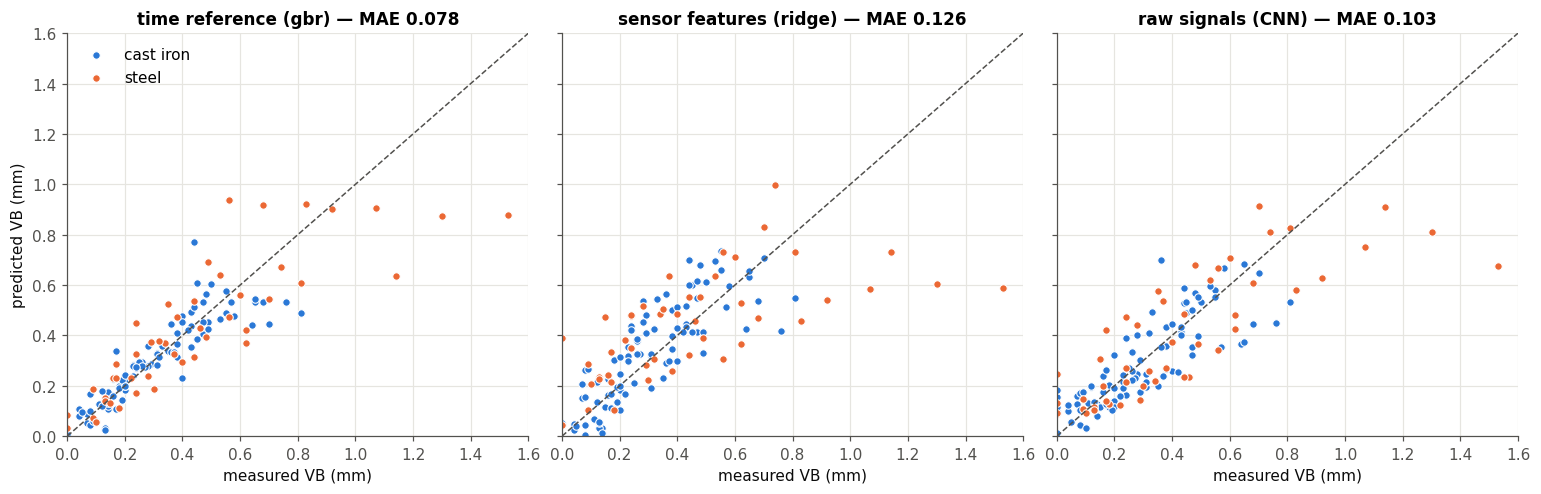

In [8]:
MODELS = {
    "time reference (gbr)": "process_time/gbr",
    "sensor features (ridge)": "sensor_process/ridge",
    "raw signals (CNN)": "sensor_process/cnn",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
lim = [0, 1.6]
for ax, (title, key) in zip(axes, MODELS.items()):
    ax.plot(lim, lim, ls="--", color=INK_MUTED, lw=1)
    for mat, c in MATERIAL_COLORS.items():
        d = oof[oof.material_name == mat]
        ax.scatter(d.target, d[key], s=24, color=c, edgecolor="white", lw=0.7, label=mat.replace("_", " "))
    mae = np.abs(oof[key] - oof.target).mean()
    ax.set(title=f"{title} — MAE {mae:.3f}", xlabel="measured VB (mm)", xlim=lim, ylim=lim)
axes[0].set_ylabel("predicted VB (mm)")
axes[0].legend()
fig.tight_layout(); save(fig, "pred_vs_true")

Points on the dashed line are perfect. All three models are good below ~0.6 mm and all **flatten out above
~0.6 mm** (points drop below the line on the right). Those high-wear points come almost only from steel cases
13 and 14 — when one of them is held out, the training set has almost no examples that worn, and regression
models don't extrapolate beyond what they've seen.

In [9]:
bins = [0, 0.2, 0.4, 0.6, 0.8, 1.6]
oof["VB_range"] = pd.cut(oof.target, bins, include_lowest=True)
err = pd.DataFrame({t: (oof[k] - oof.target).groupby(oof.VB_range, observed=True).mean() for t, k in MODELS.items()})
err["n runs"] = oof.groupby("VB_range", observed=True).size()
err.style.format("{:+.3f}", subset=list(MODELS)).set_caption("Mean signed error (bias) by true wear level, mm")

,time reference (gbr),sensor features (ridge),raw signals (CNN),n runs
VB_range,,,,
"(-0.001, 0.2]",+0.009,+0.014,+0.035,54
"(0.2, 0.4]",+0.019,+0.079,-0.001,43
"(0.4, 0.6]",+0.025,+0.048,-0.008,29
"(0.6, 0.8]",-0.135,-0.080,-0.112,11
"(0.8, 1.6]",-0.275,-0.453,-0.337,8


Signed error (bias): positive = over-predicts, negative = under-predicts. All models **over-predict a fresh
tool** slightly, start under-predicting at 0.6–0.8 mm (−0.08 to −0.14), and **strongly under-predict very worn
tools** (−0.28 to −0.45 mm above 0.8 mm; only 8 runs) — the dangerous
direction for a wear monitor, since it would report "fine" when the tool is past its limit.

## 5. Per-insert view — which held-out tools are hard?

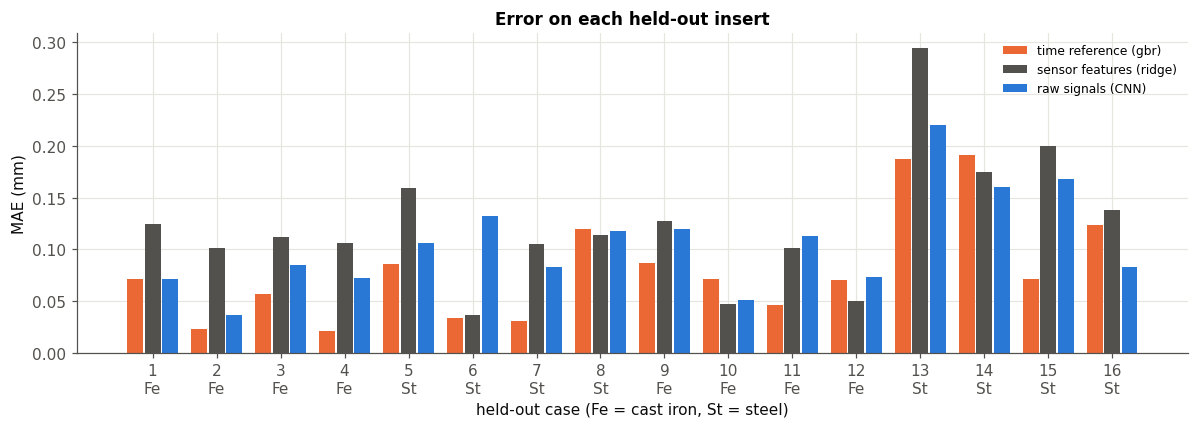

In [10]:
per_case = pd.DataFrame({
    t: (oof[k] - oof.target).abs().groupby(oof.case).mean() for t, k in MODELS.items()
})
mat = oof.groupby("case").material_name.first()
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(per_case))
w = 0.27
for i, col in enumerate(per_case.columns):
    ax.bar(x + (i - 1) * w, per_case[col], width=w * 0.92, color=[PALETTE[1], INK_MUTED, PALETTE[0]][i], label=col)
ax.set_xticks(x, [f"{c}\n{'Fe' if mat[c] == 'cast_iron' else 'St'}" for c in per_case.index])
ax.set(xlabel="held-out case (Fe = cast iron, St = steel)", ylabel="MAE (mm)", title="Error on each held-out insert")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "per_case_mae")

In [11]:
per_case.assign(material=mat).style.format("{:.3f}", subset=list(MODELS)).highlight_min(
    axis=1, subset=list(MODELS), props="font-weight:bold")

,time reference (gbr),sensor features (ridge),raw signals (CNN),material
case,,,,
1,0.071,0.124,0.071,cast_iron
2,0.023,0.101,0.036,cast_iron
3,0.056,0.112,0.084,cast_iron
4,0.021,0.106,0.073,cast_iron
5,0.086,0.159,0.107,steel
6,0.033,0.037,0.132,steel
7,0.030,0.105,0.083,steel
8,0.119,0.114,0.118,steel
9,0.087,0.127,0.120,cast_iron


* Cast-iron inserts are generally easier than steel ones for all models.
* **Steel case 13** (wears to 1.53 mm, the most in the dataset) is the hardest for every model.
* The time reference wins on most inserts, but not all: the CNN beats it on steel cases 14 and 16, and the
  ridge feature model beats it on cases 8, 10 and 12. So the sensors *do* carry information that time
  alone misses on some inserts — a hint that combining the two could beat both.

## 6. Wear trajectories of held-out inserts (CNN)
Each panel is an insert the model never saw. Blue = measured wear after each run; orange = CNN prediction
from that run's signals alone (the model is not told the previous prediction or the time).

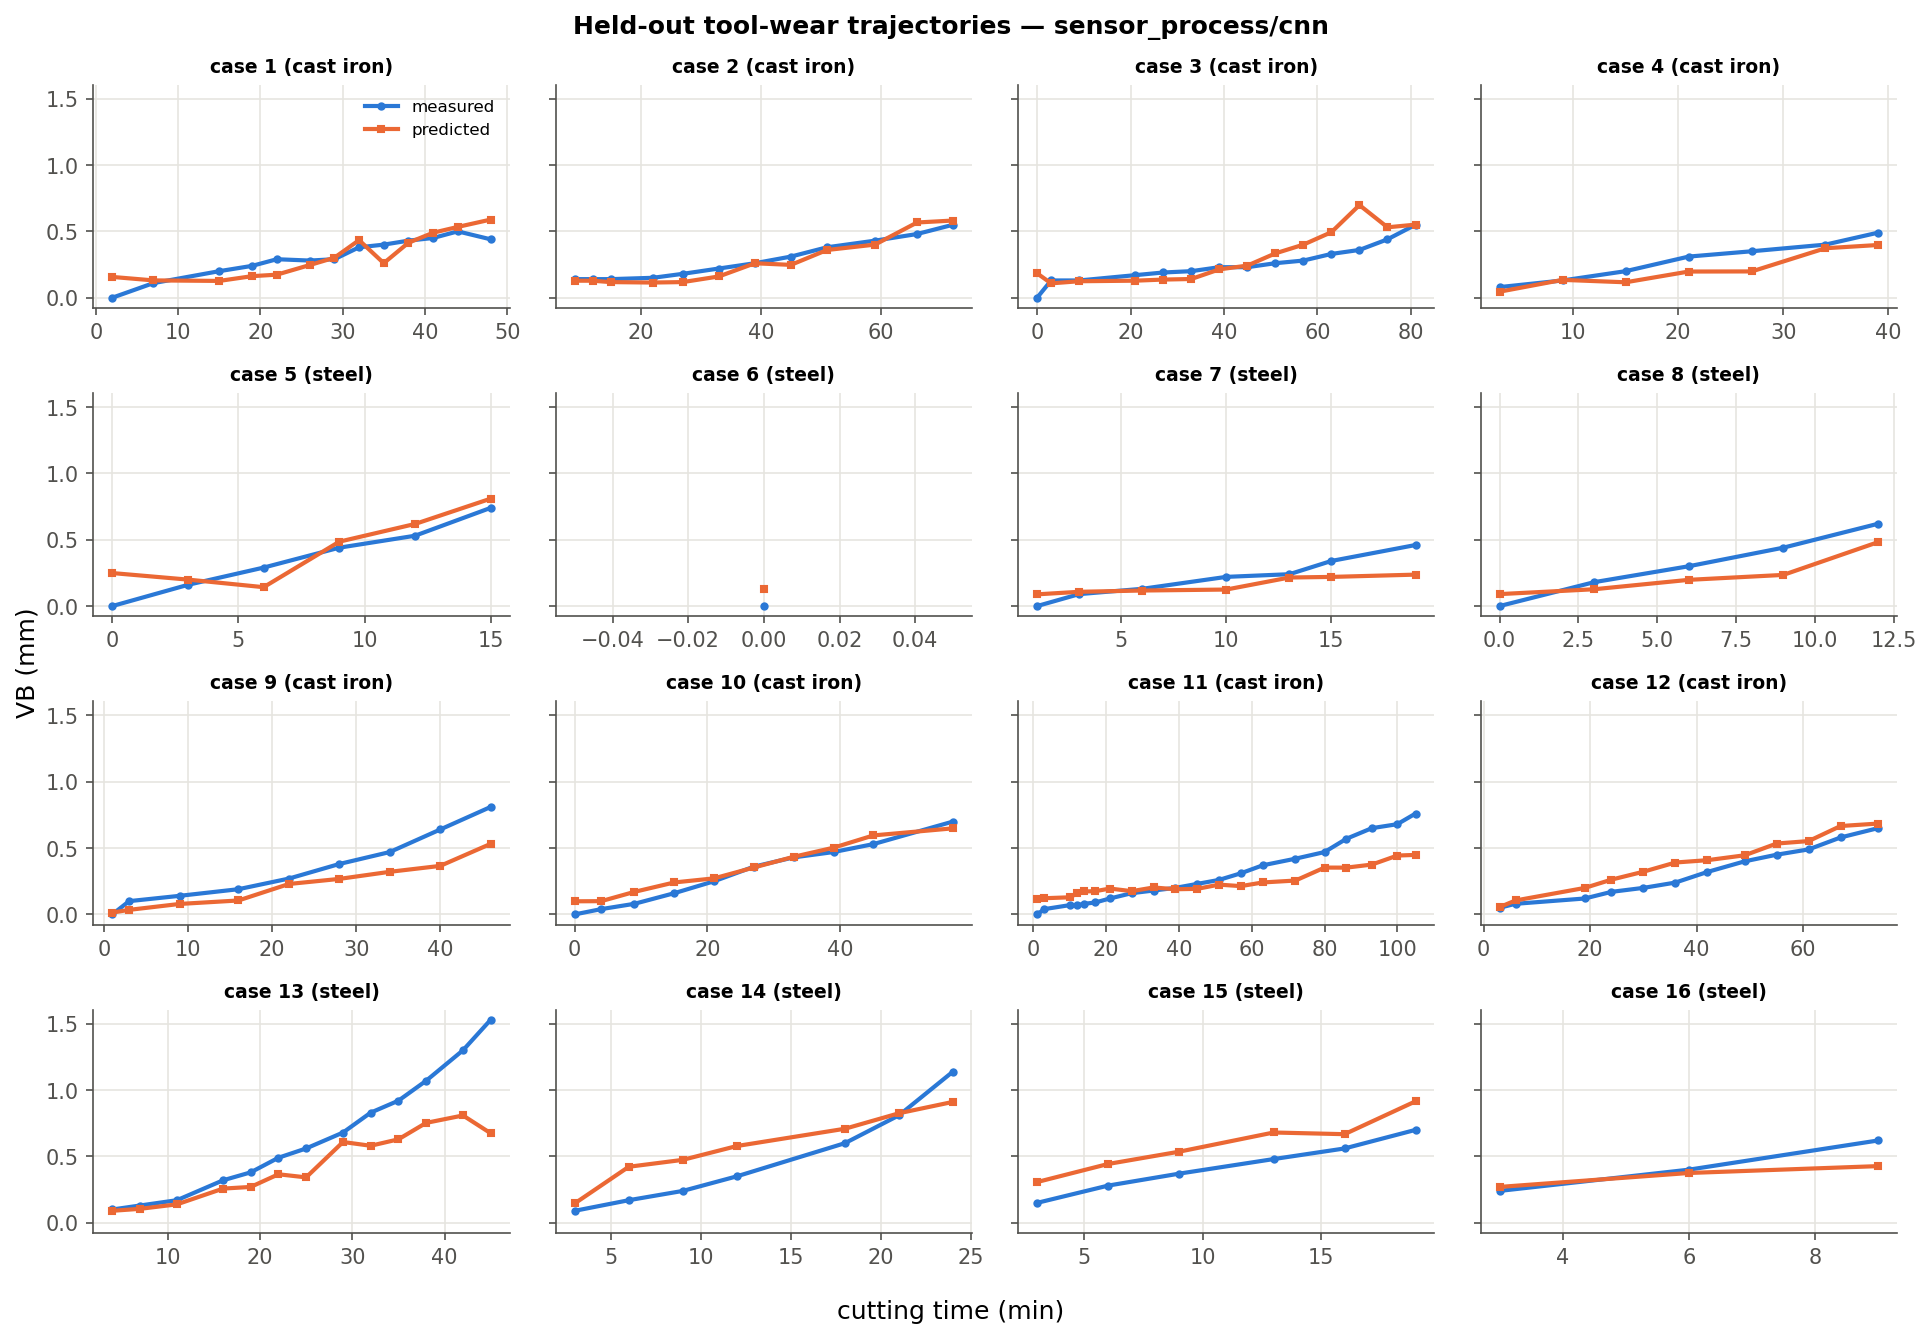

In [12]:
display(Image(FIG / "trajectories_cnn.png"))

The CNN follows the *shape* of wear growth for most inserts from signals alone. It tracks cases such as
2, 10 and 12 closely, lags late in the life of cast-iron cases 9 and 11, and falls well short on the steep
final phase of steel case 13.

## 7. What does the feature model rely on?

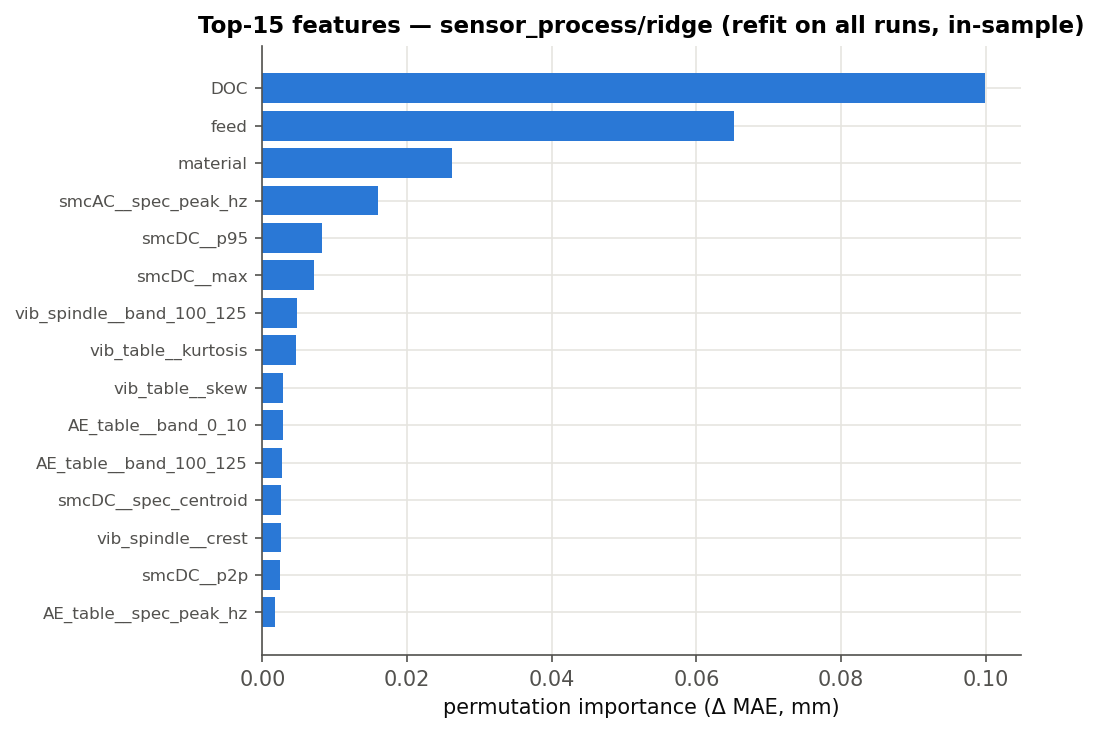

,importance
DOC,0.100
feed,0.065
material,0.026
smcAC__spec_peak_hz,0.016
smcDC__p95,0.008
smcDC__max,0.007
vib_spindle__band_100_125,0.005
vib_table__kurtosis,0.005
vib_table__skew,0.003
AE_table__band_0_10,0.003


In [13]:
imp = pd.read_csv(RES / "feature_importance.csv", index_col=0).squeeze()
display(Image(FIG / "feature_importance.png"))
imp.head(10).to_frame()

Permutation importance = how much MAE worsens when one feature is shuffled (computed on the ridge model refit
on all runs, so it is in-sample and only indicative). The settings (DOC, feed, material) rank highest because
the ridge model uses them to **re-scale** what a given current level means: the same spindle current is
"normal" at a deep steel cut and "worn" at a light cast-iron cut. Among the signals, spindle-current
features (`smcAC`, `smcDC`) dominate — consistent with the EDA (cutting force ↑ as the edge dulls).

## 8. Conclusions

1. **Sensors predict wear on unseen inserts**: best sensor model (1D-CNN) MAE ≈ 0.107 mm, R² ≈ 0.66,
   versus 0.20 mm for no skill.
2. **Learned features > hand-crafted features** here (0.107 vs 0.126 mm), and the gain is far larger than seed noise.
3. **Settings alone are useless, but settings + sensors > sensors alone** — context matters.
4. **Cutting time is a stronger predictor (0.078 mm)** in this lab dataset; a fair next step is to test whether
   sensors add information *on top of* time.
5. **Main failure mode:** under-predicting very high wear (> 0.8 mm), caused by only two inserts ever reaching it.

**Caveat:** 145 runs / 16 inserts is small. Differences of ~0.01 mm between classical models are within noise;
the ranking "no skill < sensor features < CNN < time" is the robust takeaway.